In [1]:
import myhda_ur as hda

In [2]:
hdata = hda.load_scifate()

In [3]:
top_hvg = hdata.get_highly_variable_genes(n=2000)

In [4]:
cells_hvg = hdata.get_timepoint_cells(n=100)     # 100 x 6tp = 600 cells

In [5]:
# Initialize a temporary subset object for the selected cells 
subset_cells_ = hdata[top_hvg, cells_hvg]    # 2000 genes x 600 cells

# Cell

## Total RNA

### Expression-distance clusters

gene x cell expression matrix -> distance matrix -> cluster 

In [6]:
# Compute cell-cell similarity of the selected cells using normalized gene expression values 
hdata.compute_similarity(
    data=subset_cells_,
    key="X",
    kind="cell",
    method="correlation"
)

sim1 = hdata.similarities["correlation_X_cell"]

Similarity "correlation_X_cell" stored! 



In [7]:
# Cluster the cells using Spectral Clustering
hdata.cluster_spectral(
        sim = sim1,                                 
        kind = "cell",
        k = 6
    )

cl1 = hdata.clusters["spectral_k6_cell"]

Cluster "spectral_k6_cell" stored! 



In [8]:
# Get UMAP embeddings
hdata.reduce_UMAP(
    data = subset_cells_,
    key = "X",
    kind = "cell",
    id = "exp_dist"
)

em1 = hdata.embeddings["umap_cell_exp_dist"]

UMAP embedding "umap_cell_exp_dist" stored! 



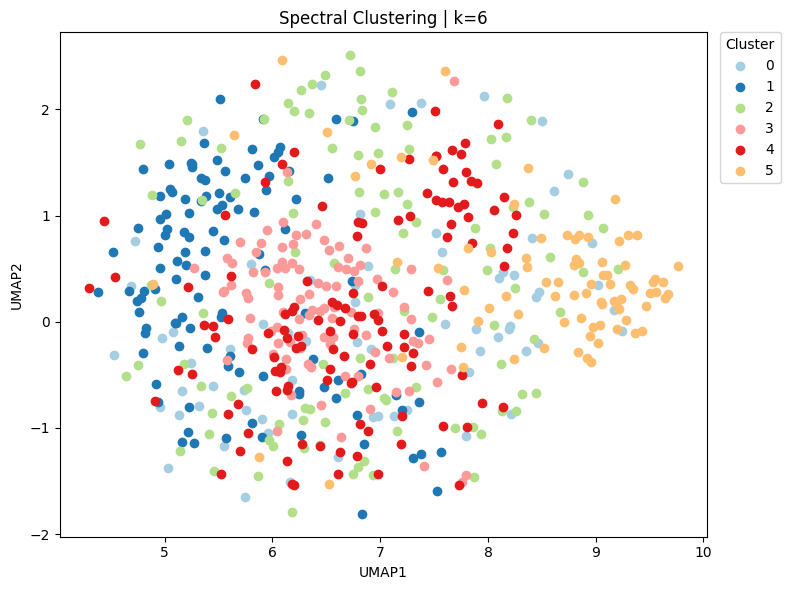

In [9]:
# Visualize 
hda.visualize.scatter(
    cluster=cl1,
    embedding=em1,
    title="Spectral Clustering | k=6",
    show_label=False
)

In [11]:
score1 = hdata.calc_cl_silhouette_score(
        cl=cl1, 
        precomputed=True, 
        sim=sim1
        )

Silhouette score: 0.00693


### PCA-based clusters 

gene x cell expression matrix -> PCA (cell x PC) -> distance matrix -> cluster

In [12]:
# PCA for representation - cell x PC matrix
hdata.compute_PCA(
    data=subset_cells_,
    key="X",
    kind="cell",
    n_pc=20
)

PCA matrix cell x 20 PCs stored in HDAData.layers["pca_cell"] 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr', 'new_rna', 'pca_cell']
  similarities: ['correlation_X_cell']
  clusters: ['spectral_k6_cell']
  embeddings: ['umap_cell_exp_dist']
  trajectories: Yes

In [13]:
# Compute cell-cell distance matrix in PC space
hdata.compute_similarity(
    data=subset_cells_,
    key="pca_cell",
    kind="cell",
    method="correlation"
)

Similarity "correlation_pca_cell_cell" stored! 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr', 'new_rna', 'pca_cell']
  similarities: ['correlation_X_cell', 'correlation_pca_cell_cell']
  clusters: ['spectral_k6_cell']
  embeddings: ['umap_cell_exp_dist']
  trajectories: Yes

In [14]:
sim2 = hdata.similarities["correlation_pca_cell_cell"]   

In [15]:
# Cluster in PC space
hdata.cluster_spectral(
    sim=sim2,
    kind="cell",
    k=6
)

cl2 = hdata.clusters["spectral_k6_cell"]

Cluster "spectral_k6_cell" stored! 



In [16]:
# Get UMAP embeddings
hdata.reduce_UMAP(
    data=subset_cells_,
    key="pca_cell",
    kind="cell",
    id="pc20"
)

UMAP embedding "umap_cell_pc20" stored! 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr', 'new_rna', 'pca_cell']
  similarities: ['correlation_X_cell', 'correlation_pca_cell_cell']
  clusters: ['spectral_k6_cell']
  embeddings: ['umap_cell_exp_dist', 'umap_cell_pc20']
  trajectories: Yes

In [17]:
em2 = hdata.embeddings["umap_cell_pc20"]

#### PC = 20

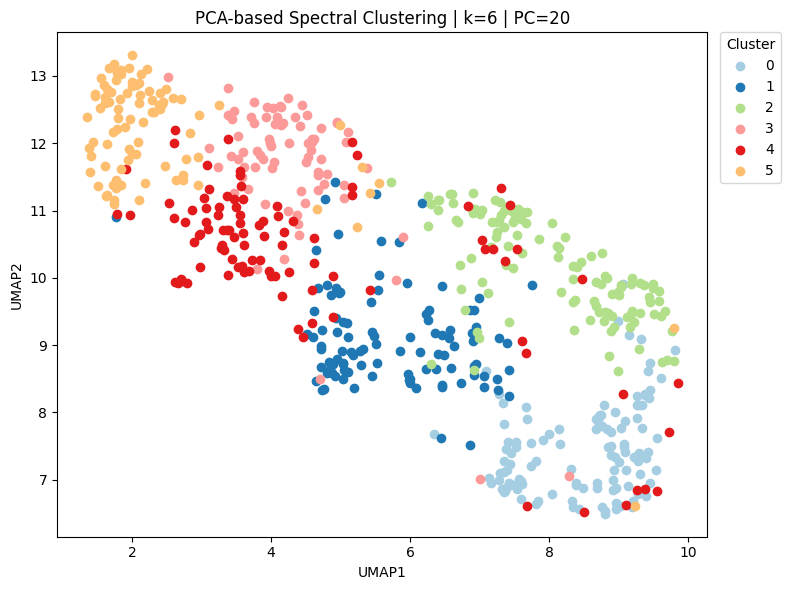

In [18]:
# Visualize 
hda.visualize.scatter(
    cluster=cl2,
    embedding=em2,
    title="PCA-based Spectral Clustering | k=6 | PC=20",
    show_label=False
)

In [19]:
score2 = hdata.calc_cl_silhouette_score(
        cl=cl2, 
        precomputed=True, 
        sim=sim2
        )

Silhouette score: 0.17002


#### PC = 5

PCA matrix cell x 5 PCs stored in HDAData.layers["pca_cell"] 

Similarity "correlation_pca_cell_cell" stored! 

Cluster "spectral_k6_cell" stored! 

UMAP embedding "umap_cell_pc5" stored! 



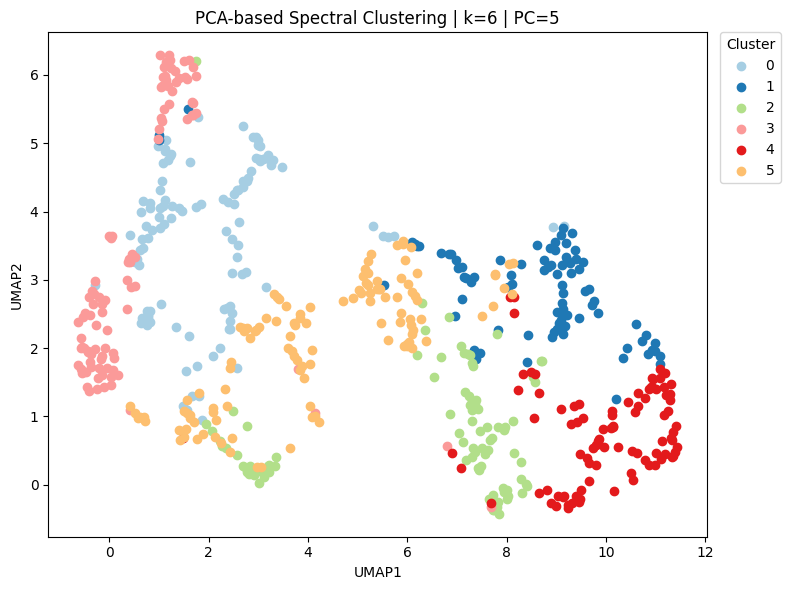

In [20]:
# PCA for representation - cell x PC matrix
hdata.compute_PCA(
    data=subset_cells_,
    key="X",
    kind="cell",
    n_pc=5
)

# Compute cell-cell distance matrix in PC space
hdata.compute_similarity(
    data=subset_cells_,
    key="pca_cell",
    kind="cell",
    method="correlation"
)

sim3 = hdata.similarities["correlation_pca_cell_cell"]   

# Cluster in PC space
hdata.cluster_spectral(
    sim=sim3,
    kind="cell",
    k=6
)

cl3 = hdata.clusters["spectral_k6_cell"]

# Get UMAP embeddings
hdata.reduce_UMAP(
    data=subset_cells_,
    key="pca_cell",
    kind="cell",
    id="pc5"
)

em3 = hdata.embeddings["umap_cell_pc5"]

# Visualize 
hda.visualize.scatter(
    cluster=cl3,
    embedding=em3,
    title="PCA-based Spectral Clustering | k=6 | PC=5",
    show_label=False
)

In [21]:
score3 = hdata.calc_cl_silhouette_score(
        cl=cl3, 
        precomputed=True, 
        sim=sim3
        )

Silhouette score: 0.39348


#### PC = 50

PCA matrix cell x 50 PCs stored in HDAData.layers["pca_cell"] 

Similarity "correlation_pca_cell_cell" stored! 

Cluster "spectral_k6_cell" stored! 

UMAP embedding "umap_cell_pc5" stored! 



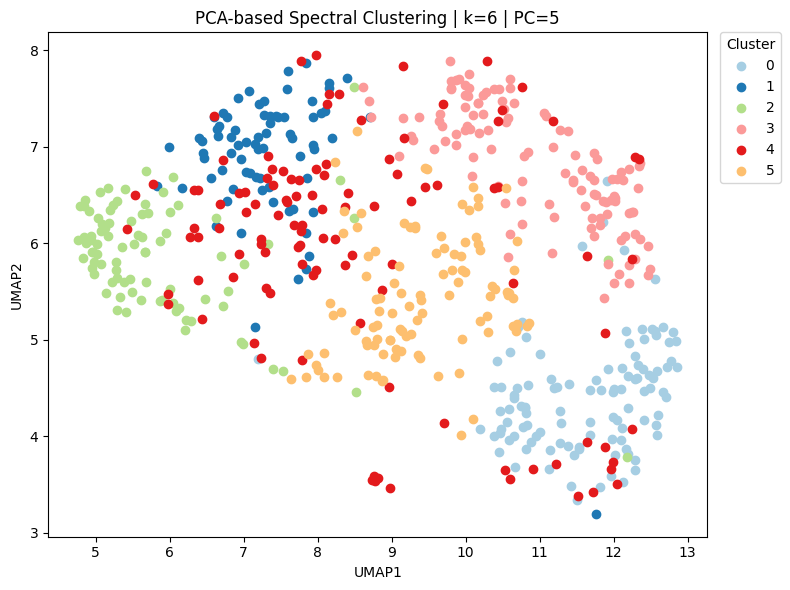

In [23]:
# PCA for representation - cell x PC matrix
hdata.compute_PCA(
    data=subset_cells_,
    key="X",
    kind="cell",
    n_pc=50
)

# Compute cell-cell distance matrix in PC space
hdata.compute_similarity(
    data=subset_cells_,
    key="pca_cell",
    kind="cell",
    method="correlation"
)

sim4 = hdata.similarities["correlation_pca_cell_cell"]   

# Cluster in PC space
hdata.cluster_spectral(
    sim=sim4,
    kind="cell",
    k=6
)

cl4 = hdata.clusters["spectral_k6_cell"]

# Get UMAP embeddings
hdata.reduce_UMAP(
    data=subset_cells_,
    key="pca_cell",
    kind="cell",
    id="pc5"
)

em4 = hdata.embeddings["umap_cell_pc5"]

# Visualize 
hda.visualize.scatter(
    cluster=cl4,
    embedding=em4,
    title="PCA-based Spectral Clustering | k=6 | PC=5",
    show_label=False
)

In [24]:
score4 = hdata.calc_cl_silhouette_score(
        cl=cl4, 
        precomputed=True, 
        sim=sim4
        )

Silhouette score: 0.09889


### Compare different PC

![img1aa](temp/img1aa.jpg)

## New RNA

#### PC = 20

PCA matrix cell x 20 PCs stored in HDAData.layers["pca_cell"] 

Similarity "correlation_pca_cell_cell" stored! 

Cluster "spectral_k6_cell" stored! 

UMAP embedding "umap_cell_pc20" stored! 



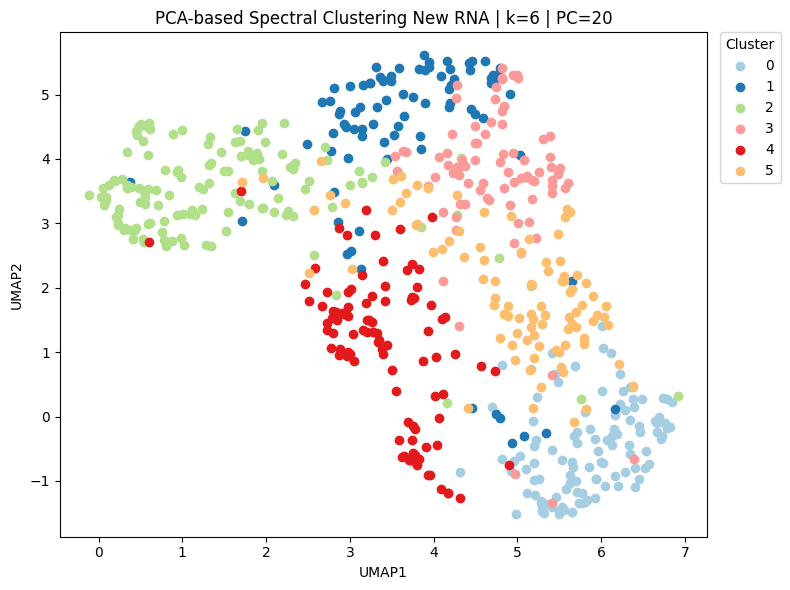

In [25]:
# PCA on new RNA
hdata.compute_PCA(
    data=subset_cells_,
    key="new_rna",      
    kind="cell",
    n_pc=20
)

pc_matrix = hdata.layers["pca_cell"]  

# Compute cell-cell distance matrix in PC space
hdata.compute_similarity(
    data=subset_cells_,
    key="pca_cell",
    kind="cell",
    method="correlation"
)

sim5 = hdata.similarities["correlation_pca_cell_cell"]   

# Cluster in PC space
hdata.cluster_spectral(
    sim=sim5,
    kind="cell",
    k=6
)

cl5 = hdata.clusters["spectral_k6_cell"]

# Get UMAP embeddings
hdata.reduce_UMAP(
    data=subset_cells_,
    key="pca_cell",
    kind="cell",
    id = "pc20"
)

em5= hdata.embeddings["umap_cell_pc20"] 

# Visualize 
hda.visualize.scatter(
    cluster=cl5,
    embedding=em5,
    title="PCA-based Spectral Clustering New RNA | k=6 | PC=20",
    show_label=False
)

In [26]:
score5 = hdata.calc_cl_silhouette_score(
        cl=cl5, 
        precomputed=True, 
        sim=sim5
        )

Silhouette score: 0.15001


### Compare Total RNA vs New RNA

![img1bb](temp/img1bb.jpg)